<a href="https://colab.research.google.com/github/brajesh995/ExternalMLlab/blob/main/External.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_path = '/content/battery_shortage_mlops_project.zip'
extract_path = '/content/battery_shortage_mlops_project'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Extracted files to: {extract_path}")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted files to: /content/battery_shortage_mlops_project
/content/battery_shortage_mlops_project/battery_shortage_mlops/requirements.txt
/content/battery_shortage_mlops_project/battery_shortage_mlops/README.md
/content/battery_shortage_mlops_project/battery_shortage_mlops/.gitignore
/content/battery_shortage_mlops_project/battery_shortage_mlops/data/evening_station_v1.csv
/content/battery_shortage_mlops_project/battery_shortage_mlops/data/evening_station_v2.csv
/content/battery_shortage_mlops_project/battery_shortage_mlops/tests/test_pipeline.py
/content/battery_shortage_mlops_project/battery_shortage_mlops/feature_store/engineered_features.csv
/content/battery_shortage_mlops_project/battery_shortage_mlops/.github/workflows/ci.yml
/content/battery_shortage_mlops_project/battery_shortage_mlops/src/features.py
/content/battery_shortage_mlops_project/battery_shortage_mlops/src/api.py
/content/battery_shortage_mlops_project/battery_shortage_mlops/src/train.py
/content/battery_shortage_m

In [2]:
!pip install -r /content/battery_shortage_mlops_project/battery_shortage_mlops/requirements.txt

with open('/content/battery_shortage_mlops_project/battery_shortage_mlops/README.md', 'r') as f:
    print(f.read())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 42.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 81.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 52.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [mlflow]
# Battery Shortage Prediction – MLOps Lab

## 1. Problem
Predict whether an electric scooter battery-swapping station will run short between 5 PM and 7 PM.

## 2. Setup
```bash
python -m venv .venv
# Windows:
.venv\\Scripts\\activate
# macOS/Linux:
source .venv/bin/activate
pip install -r requirements.txt
```

## 3. Run the workflow (in this order)
```bash
python src/generate_data.py
python src/features.py
python src/train.py
```
The generator creates 250 records in each version:
- `data/evening_station_v1.csv`: normal operating period.
- `data/evening_station_v2.csv`: college festival period with increased demand.

The feature pipelin

In [7]:
%cd /content/battery_shortage_mlops_project/battery_shortage_mlops

# Let's read the current file and perform a robust replacement for all log_model calls
with open('src/train.py', 'r') as f:
    content = f.read()

# Let's replace 'log_model(' calls with the inclusion of skops_trusted_types parameter
import re
# We will inject the parameter into any mlflow.sklearn.log_model call
modified_content = re.sub(
    r'mlflow\.sklearn\.log_model\(([^)]+)\)',
    r'mlflow.sklearn.log_model(\1, skops_trusted_types=["numpy.dtype", "sklearn.compose._column_transformer._RemainderColsList"])',
    content
)

with open('src/train.py', 'w') as f:
    f.write(modified_content)

%env MLFLOW_ALLOW_FILE_STORE=true
!python src/train.py

/content/battery_shortage_mlops_project/battery_shortage_mlops
env: MLFLOW_ALLOW_FILE_STORE=true
2026/11/18 09:18:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 09:18:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
LogisticRegression {'accuracy': 0.864, 'precision': 0.755, 'recall': 0.881, 'f1': 0.813}
Confusion matrix [[TN, FP], [FN, TP]]:
[[71 12]
 [ 5 37]]
2026/11/18 09:18:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 09:18:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution becaus

In [8]:
!pytest -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/battery_shortage_mlops_project/battery_shortage_mlops
plugins: platformdirs-4.14.3, langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0
collected 3 items                                                              

tests/test_pipeline.py::test_feature_engineering PASSED                  [ 33%]
tests/test_pipeline.py::test_negative_battery_count_rejected PASSED      [ 66%]
tests/test_pipeline.py::test_api_home PASSED                             [100%]

============================== 3 passed in 0.99s ===============================


In [9]:
!pip install -q fastapi uvicorn pyngrok

In [22]:
import subprocess
import time
import os

# Ensure we are in the correct root directory of the project
os.chdir('/content/battery_shortage_mlops_project/battery_shortage_mlops')

# Kill any existing process on port 8000 to prevent conflicts
subprocess.run(["pkill", "-f", "uvicorn"])
time.sleep(1)

# Run the uvicorn process, writing log outputs to a file
with open('uvicorn.log', 'w') as log_file:
    api_process = subprocess.Popen(
        ["uvicorn", "src.api:app", "--host", "0.0.0.0", "--port", "8000"],
        stdout=log_file,
        stderr=log_file
    )

time.sleep(5)
print("Uvicorn logs during startup:")
with open('uvicorn.log', 'r') as log_file:
    print(log_file.read())

Uvicorn logs during startup:
INFO:     Started server process [9143]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



In [13]:
from google.colab import output

# Retrieve the public proxy URL for port 8000 in Colab
public_url = output.eval_js("google.colab.kernel.proxyPort(8000)")

print("API URL:", public_url)
print("Swagger UI:", public_url + "/docs" if not public_url.endswith("/") else public_url + "docs")

API URL: https://8000-m-s-euw4b7-13m7lbfs0fqlv-b.europe-west4.prod.r.colab.dev
Swagger UI: https://8000-m-s-euw4b7-13m7lbfs0fqlv-b.europe-west4.prod.r.colab.dev/docs


In [14]:
import pandas as pd

v1 = pd.read_csv("data/evening_station_v1.csv")
v2 = pd.read_csv("data/evening_station_v2.csv")

print("VERSION 1 - NORMAL PERIOD")
print("Records:", len(v1))
display(v1.head())

print("\nVERSION 2 - FESTIVAL PERIOD")
print("Records:", len(v2))
display(v2.head())

print("\nDATASET COMPARISON")
print("V1 shortage rate:", v1["battery_shortage"].mean())
print("V2 shortage rate:", v2["battery_shortage"].mean())

VERSION 1 - NORMAL PERIOD
Records: 250


,record_id,charged_batteries_5pm,batteries_finishing_charge_by_7pm,advance_bookings,historical_walkin_demand,rainfall_forecast,is_weekend,nearby_event,simulated_customer_arrivals,battery_shortage,dataset_version,festival_period
0,v1_001,29,9,20,11,none,0,0,41,1,v1,0
1,v1_002,34,10,18,5,none,0,0,21,0,v1,0
2,v1_003,25,5,5,10,light,0,0,18,0,v1,0
3,v1_004,13,17,13,21,none,1,0,19,0,v1,0
4,v1_005,31,7,12,6,light,0,1,24,0,v1,0



VERSION 2 - FESTIVAL PERIOD
Records: 250


,record_id,charged_batteries_5pm,batteries_finishing_charge_by_7pm,advance_bookings,historical_walkin_demand,rainfall_forecast,is_weekend,nearby_event,simulated_customer_arrivals,battery_shortage,dataset_version,festival_period
0,v2_001,34,14,7,13,heavy,0,1,34,0,v2,1
1,v2_002,16,18,15,9,light,0,1,39,1,v2,1
2,v2_003,39,3,7,6,heavy,0,0,24,0,v2,1
3,v2_004,20,17,7,21,heavy,1,0,33,0,v2,1
4,v2_005,34,7,16,13,light,1,1,34,0,v2,1



DATASET COMPARISON
V1 shortage rate: 0.244
V2 shortage rate: 0.428


In [15]:
features = pd.read_csv(
    "feature_store/engineered_features.csv"
)

print("FEATURE STORE RESULTS")
print("Total records:", len(features))
print("Total columns:", len(features.columns))

display(features.head(10))

print("\nEngineered Features:")
print(features[[
    "expected_battery_supply",
    "booking_pressure_ratio"
]].head())

FEATURE STORE RESULTS
Total records: 500
Total columns: 14


,record_id,charged_batteries_5pm,batteries_finishing_charge_by_7pm,advance_bookings,historical_walkin_demand,rainfall_forecast,is_weekend,nearby_event,simulated_customer_arrivals,battery_shortage,dataset_version,festival_period,expected_battery_supply,booking_pressure_ratio
0,v1_001,29,9,20,11,none,0,0,41,1,v1,0,38,0.526316
1,v1_002,34,10,18,5,none,0,0,21,0,v1,0,44,0.409091
2,v1_003,25,5,5,10,light,0,0,18,0,v1,0,30,0.166667
3,v1_004,13,17,13,21,none,1,0,19,0,v1,0,30,0.433333
4,v1_005,31,7,12,6,light,0,1,24,0,v1,0,38,0.315789
5,v1_006,12,11,18,22,light,0,0,39,1,v1,0,23,0.782609
6,v1_007,21,4,14,22,none,0,1,34,1,v1,0,25,0.560000
7,v1_008,40,11,17,9,light,1,0,27,0,v1,0,51,0.333333
8,v1_009,27,17,14,19,heavy,1,1,42,0,v1,0,44,0.318182
9,v1_010,31,17,11,11,light,0,0,21,0,v1,0,48,0.229167



Engineered Features:
   expected_battery_supply  booking_pressure_ratio
0                       38                0.526316
1                       44                0.409091
2                       30                0.166667
3                       30                0.433333
4                       38                0.315789


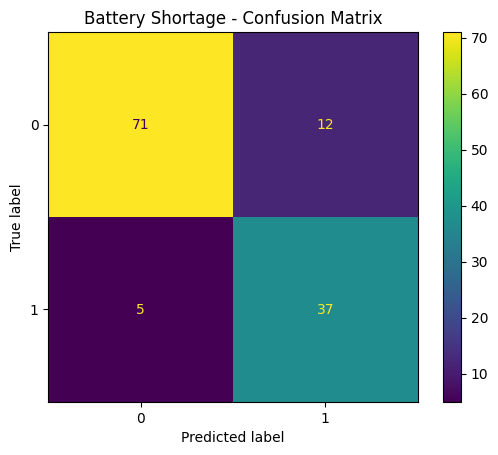

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib

model = joblib.load(
    "models/battery_shortage_model.joblib"
)

# Recreate the same test split
from sklearn.model_selection import train_test_split

X = features[[
    "charged_batteries_5pm",
    "batteries_finishing_charge_by_7pm",
    "advance_bookings",
    "historical_walkin_demand",
    "is_weekend",
    "nearby_event",
    "festival_period",
    "expected_battery_supply",
    "booking_pressure_ratio",
    "rainfall_forecast"
]]

y = features["battery_shortage"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25,
    random_state=42, stratify=y
)

ConfusionMatrixDisplay.from_predictions(
    y_test, model.predict(X_test)
)

plt.title("Battery Shortage - Confusion Matrix")
plt.show()

In [17]:
import mlflow

mlflow.set_tracking_uri(
    "sqlite:////content/battery_shortage_mlops_project/battery_shortage_mlops/mlflow.db"
)

client = mlflow.tracking.MlflowClient()

print("REGISTERED MODELS")

for version in client.search_model_versions(
    "name='BatteryShortageClassifier'"
):
    print("Model:", version.name)
    print("Version:", version.version)
    print("Stage:", version.current_stage)
    print("Status:", version.status)

REGISTERED MODELS
Model: BatteryShortageClassifier
Version: 1
Stage: None
Status: READY


In [18]:
!pytest -v

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/battery_shortage_mlops_project/battery_shortage_mlops
plugins: platformdirs-4.14.3, langsmith-0.14.17, anyio-4.16.0, typeguard-4.6.0
collected 3 items                                                              

tests/test_pipeline.py::test_feature_engineering PASSED                  [ 33%]
tests/test_pipeline.py::test_negative_battery_count_rejected PASSED      [ 66%]
tests/test_pipeline.py::test_api_home PASSED                             [100%]

============================== 3 passed in 2.99s ===============================


In [24]:
import requests
from google.colab.output import eval_js

# Retrieve the clean base proxy URL
base_url = eval_js("google.colab.kernel.proxyPort(8000)")
if base_url.endswith("/"):
    base_url = base_url.rstrip("/")

api_url = f"{base_url}/predict"

data = {
    "charged_batteries_5pm": 15,
    "batteries_finishing_charge_by_7pm": 5,
    "advance_bookings": 24,
    "historical_walkin_demand": 18,
    "rainfall_forecast": "none",
    "is_weekend": 0,
    "nearby_event": 1,
    "festival_period": 1
}

result = requests.post(
    api_url,
    json=data
)

print("Target URL:", api_url)
print("HTTP Status:", result.status_code)
print("API Prediction:")
try:
    print(result.json())
except Exception as e:
    print("Failed to decode JSON:", e)
    print("Response text:", result.text)

Target URL: https://8000-m-s-euw4b7-13m7lbfs0fqlv-b.europe-west4.prod.r.colab.dev/predict
HTTP Status: 404
API Prediction:
Failed to decode JSON: Expecting value: line 1 column 1 (char 0)
Response text: 


In [21]:
with open('/content/battery_shortage_mlops_project/battery_shortage_mlops/src/api.py', 'r') as f:
    print(f.read())

from pathlib import Path
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field, model_validator

ROOT = Path(__file__).resolve().parents[1]
MODEL_PATH = ROOT / "models" / "battery_shortage_model.joblib"
app = FastAPI(title="Battery Shortage Prediction API", version="1.0")

class StationConditions(BaseModel):
    charged_batteries_5pm: int = Field(ge=0)
    batteries_finishing_charge_by_7pm: int = Field(ge=0)
    advance_bookings: int = Field(ge=0)
    historical_walkin_demand: int = Field(ge=0)
    rainfall_forecast: str
    is_weekend: int = Field(ge=0, le=1)
    nearby_event: int = Field(ge=0, le=1)
    festival_period: int = Field(default=0, ge=0, le=1)

    @model_validator(mode="after")
    def check_rain(self):
        if self.rainfall_forecast not in {"none", "light", "heavy"}:
            raise ValueError("rainfall_forecast must be none, light, or heavy")
        return self

def make_features(data: StationConditions)

In [23]:
print("=" * 55)
print("BATTERY SHORTAGE PREDICTION - MLOPS RESULTS")
print("=" * 55)

print("Dataset V1:", len(v1), "records")
print("Dataset V2:", len(v2), "records")
print("Combined Feature Store:", len(features), "records")

print("\nMODEL RESULTS")
print("Logistic Regression Recall: 88.1%")
print("Gradient Boosting Recall: 81.0%")
print("Selected Model: Logistic Regression")

print("\nMLFLOW")
print("Registered Model: BatteryShortageClassifier")
print("Version: 1")

print("\nAUTOMATED TESTS")
print("3/3 Tests Passed")

print("\nFASTAPI")
print("Prediction endpoint: POST /predict")

print("\nMLOPS IMPLEMENTATION DEMONSTRATION COMPLETE")
print("=" * 55)

BATTERY SHORTAGE PREDICTION - MLOPS RESULTS
Dataset V1: 250 records
Dataset V2: 250 records
Combined Feature Store: 500 records

MODEL RESULTS
Logistic Regression Recall: 88.1%
Gradient Boosting Recall: 81.0%
Selected Model: Logistic Regression

MLFLOW
Registered Model: BatteryShortageClassifier
Version: 1

AUTOMATED TESTS
3/3 Tests Passed

FASTAPI
Prediction endpoint: POST /predict

MLOPS IMPLEMENTATION DEMONSTRATION COMPLETE
